# Local Volatility Model for Equity Option Pricing

This notebook builds a **Dupire local volatility model** from a synthetic implied volatility smile, then prices European calls with it by solving the pricing PDE.

**Pipeline**

1. Define an arbitrage-free implied volatility smile (raw SVI).
2. Generate a grid of European call prices with Black-Scholes.
3. Recover the local volatility surface with **Dupire's formula**, using finite differences on the price grid.
4. Price calls under local volatility by solving the **pricing PDE** with an implicit finite-difference scheme.
5. **Round-trip test**: the local vol prices should match the Black-Scholes prices of the smile they were built from.
6. **Application**: delta hedging with the local vol model, when the world follows local vol and when it follows a stochastic volatility model (Heston).

A last section summarizes the tests run on **real market data** (S&P 500 options).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.linalg import solve_banded
from scipy.interpolate import RegularGridInterpolator

# Market parameters
S0 = 100
r = 0.02      # risk-free rate
q = 0.05      # continuous dividend yield
T_test = 1.0  # maturity used to define the smile and for the tests

## 1. Synthetic implied volatility smile

The smile is a **raw SVI** parameterization of the implied variance, in log-moneyness $k = \ln(K/F)$ with $F = S_0 e^{(r-q)T}$:

$$
\sigma_{\text{imp}}^2(k) = a + b\left[\rho (k - m) + \sqrt{(k - m)^2 + s^2}\right]
$$

A first version used a parabola in $k$. It looks harmless, but the implied variance then grows like $k^4$ in the wings, which violates **Lee's moment formula** (total variance can grow at most linearly in $|k|$). The implied risk-neutral probability $\mathbb{P}(S_T > K)$ exceeded 1 for low strikes: no diffusion model can reproduce such prices. SVI has linear wings and, for $b(1 + |\rho|)T < 2$, stays within Lee's bound.

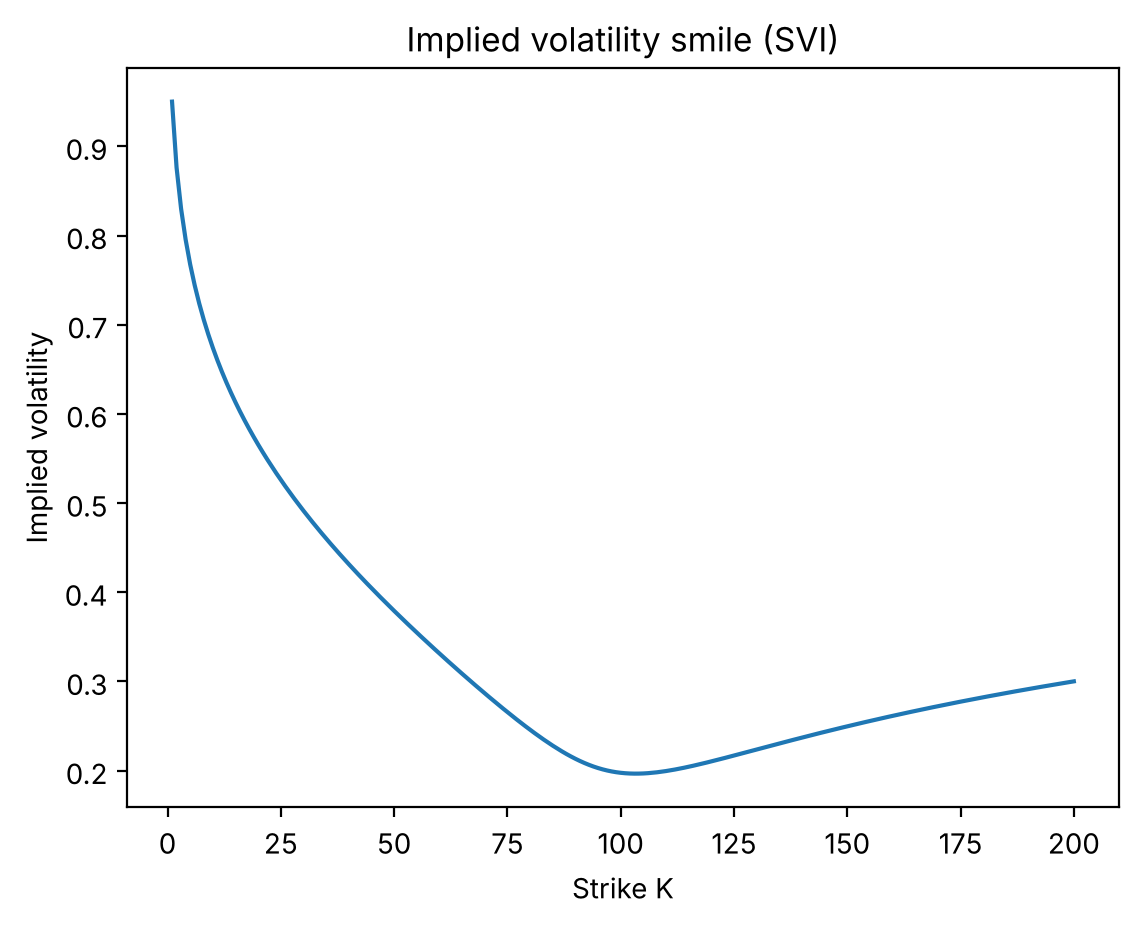

In [2]:
a, b, rho, m, s = 0.01, 0.15, -0.3, 0.0, 0.2   # ATM vol ≈ 0.20; b*(1+|rho|)*T = 0.195 (< 2)

def implied_vol(K):
    F = S0 * np.exp((r - q) * T_test)
    k = np.log(K / F)
    return np.sqrt(a + b * (rho * (k - m) + np.sqrt((k - m)**2 + s**2)))

K_grid = np.arange(1, 201, 1)
T_grid = np.arange(0, 1.01, 0.01)  # maturities from 0 to 1 year

plt.plot(K_grid, implied_vol(K_grid))
plt.xlabel('Strike K')
plt.ylabel('Implied volatility')
plt.title('Implied volatility smile (SVI)')
plt.show()

## 2. Black-Scholes call price surface

Each strike is priced with its smile volatility. The smile does not depend on maturity: the same implied vol is used for every $T$.

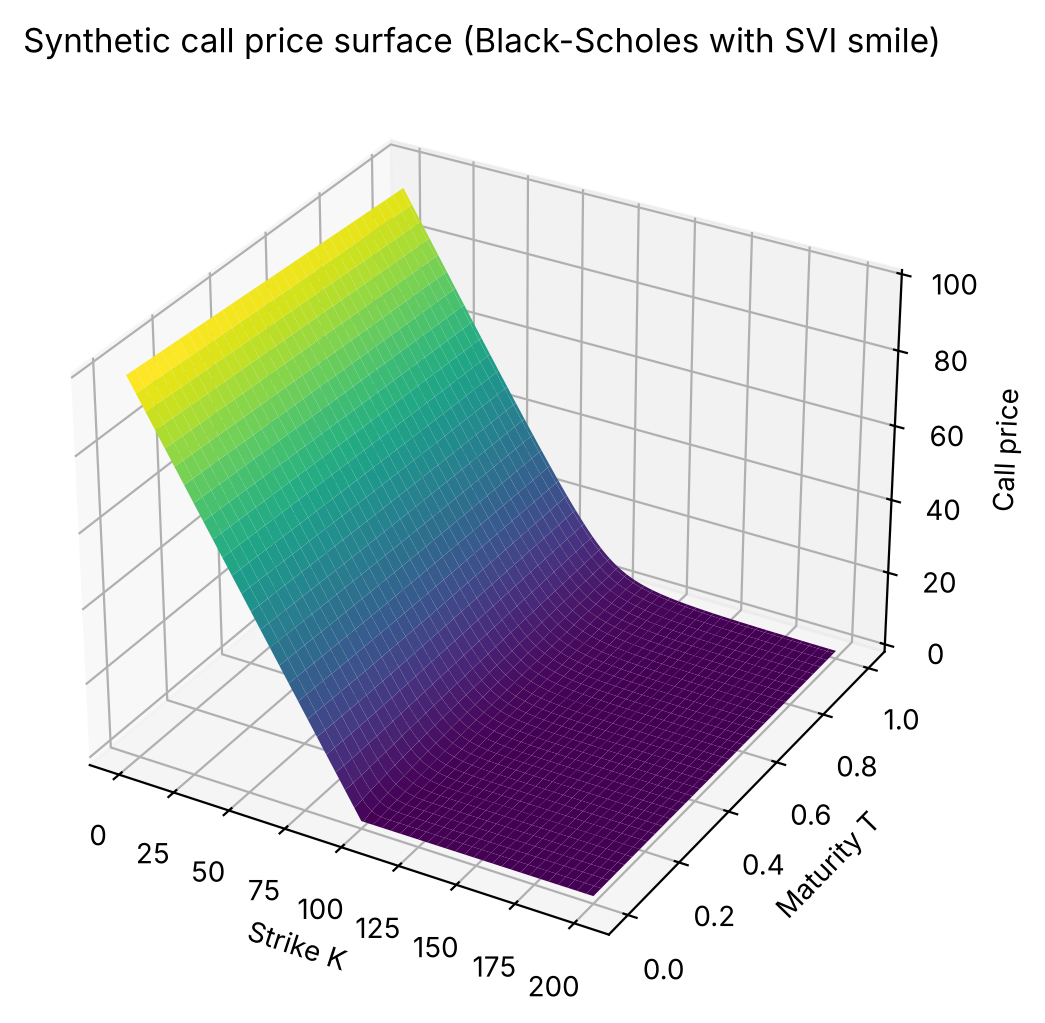

In [3]:
def bs_price(S, K, T, r, q, sigma, option_type='call'):
    # Black-Scholes price of a European option with continuous dividend yield q
    if T == 0:
        if option_type == 'call':
            return max(S - K, 0)
        elif option_type == 'put':
            return max(K - S, 0)
        else:
            raise ValueError("option_type must be 'call' or 'put'")
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    if option_type == 'call':
        price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    elif option_type == 'put':
        price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)
    else:
        raise ValueError("option_type must be 'call' or 'put'")
    return price

price_list = []
for K in K_grid:
    sigma = implied_vol(K)
    maturity = []
    for t in T_grid:
        maturity.append(bs_price(S0, K, t, r, q, sigma, option_type='call'))
    price_list.append(maturity)
price_list = np.array(price_list)   # shape (len(K_grid), len(T_grid))

K_mesh, T_mesh = np.meshgrid(K_grid, T_grid)
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(K_mesh, T_mesh, price_list.T, cmap="viridis")
ax.set_xlabel("Strike K")
ax.set_ylabel("Maturity T")
ax.set_zlabel("Call price")
ax.set_title("Synthetic call price surface (Black-Scholes with SVI smile)")
plt.show()

## 3. Dupire local volatility

With a continuous dividend yield, Dupire's formula gives the local volatility from call prices:

$$
\sigma_{\text{loc}}^2(K, T) = \frac{\dfrac{\partial C}{\partial T} + (r - q) K \dfrac{\partial C}{\partial K} + q C}{\dfrac{1}{2} K^2 \dfrac{\partial^2 C}{\partial K^2}}
$$

The derivatives are computed with second-order finite differences: central inside the grid, one-sided (forward or backward) on its edges. Points where the denominator (the risk-neutral density) is too small or the numerator is negative are set to NaN.

The local volatility is **not** the implied volatility: the implied vol of an option is roughly an average of the local vol along the paths that matter for that option. As a rule of thumb, the local vol skew is about twice the implied vol skew.

Share of NaN points: 9.1%


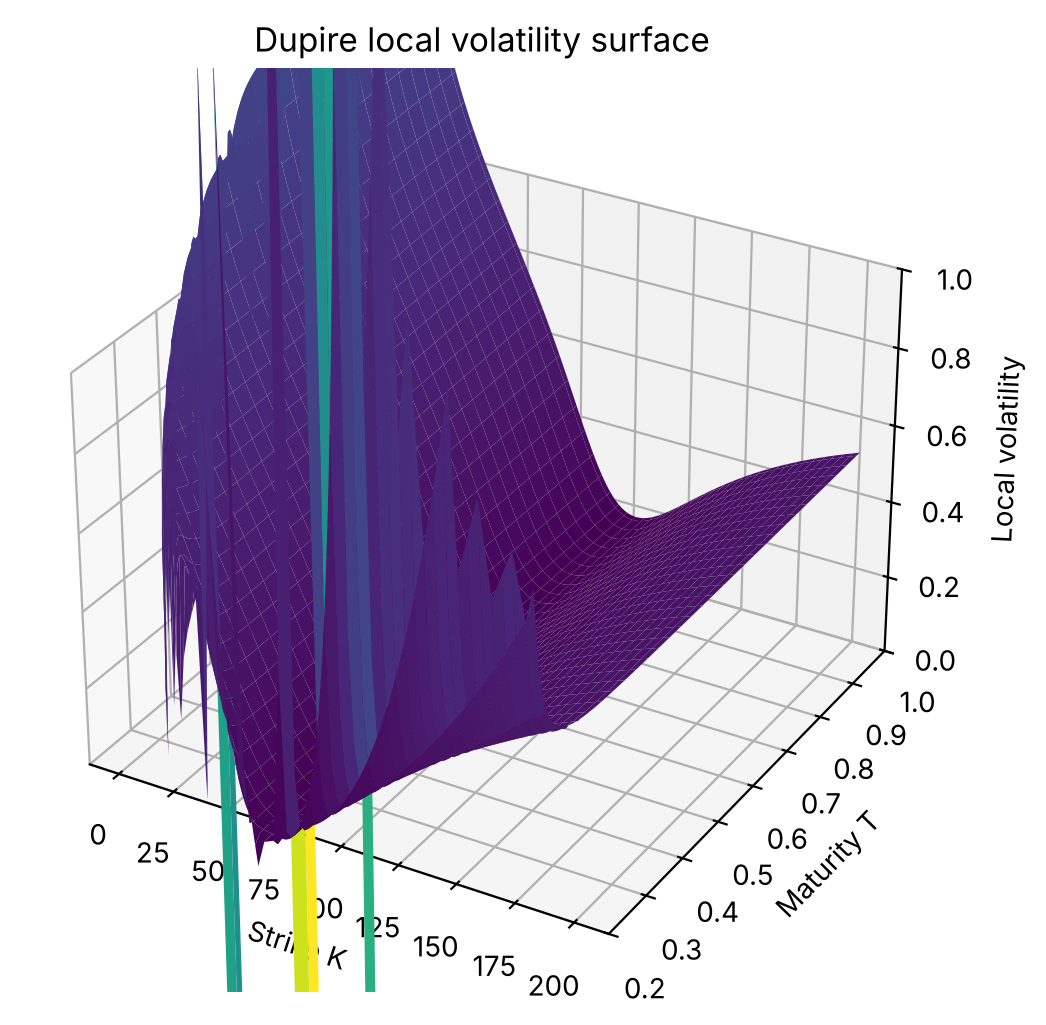

In [4]:
def d1(f, h, axis):
    # Second-order first derivative along `axis` (uniform grid with step h)
    f = np.moveaxis(f, axis, 0)
    out = np.empty_like(f)
    out[1:-1] = (f[2:] - f[:-2]) / (2 * h)                  # central
    out[0]  = (-3 * f[0] + 4 * f[1] - f[2]) / (2 * h)       # forward
    out[-1] = (3 * f[-1] - 4 * f[-2] + f[-3]) / (2 * h)     # backward
    return np.moveaxis(out, 0, axis)

def d2(f, h, axis):
    # Second-order second derivative along `axis` (uniform grid with step h)
    f = np.moveaxis(f, axis, 0)
    out = np.empty_like(f)
    out[1:-1] = (f[2:] - 2 * f[1:-1] + f[:-2]) / h**2                    # central
    out[0]  = (2 * f[0] - 5 * f[1] + 4 * f[2] - f[3]) / h**2             # forward
    out[-1] = (2 * f[-1] - 5 * f[-2] + 4 * f[-3] - f[-4]) / h**2         # backward
    return np.moveaxis(out, 0, axis)

def local_vol(C, K_grid, T_grid, r, q, tol=1e-12):
    # Dupire local volatility surface, NaN where the formula is not usable
    K_grid, T_grid, C = (np.asarray(x, float) for x in (K_grid, T_grid, C))
    hK, hT = K_grid[1] - K_grid[0], T_grid[1] - T_grid[0]
    if not (np.allclose(np.diff(K_grid), hK) and np.allclose(np.diff(T_grid), hT)):
        raise ValueError("K and T grids must be uniform.")
    if len(K_grid) < 4 or len(T_grid) < 3:
        raise ValueError("At least 4 strikes and 3 maturities are required.")
    if C.shape != (len(K_grid), len(T_grid)):
        raise ValueError("C must have shape (len(K_grid), len(T_grid)).")

    dC_dK   = d1(C, hK, axis=0)
    d2C_dK2 = d2(C, hK, axis=0)
    dC_dT   = d1(C, hT, axis=1)

    K = K_grid[:, None]                       # broadcast over maturities
    num = dC_dT + (r - q) * K * dC_dK + q * C
    den = 0.5 * K**2 * d2C_dK2

    vol = np.full_like(C, np.nan)
    ok = (den > tol) & (num > 0)
    vol[ok] = np.sqrt(num[ok] / den[ok])
    return vol

vol = local_vol(price_list, K_grid, T_grid, r, q)
print(f"Share of NaN points: {np.isnan(vol).mean():.1%}")

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(K_mesh, T_mesh, vol.T, cmap="viridis")
ax.set_xlabel("Strike K")
ax.set_ylabel("Maturity T")
ax.set_zlabel("Local volatility")
ax.set_ylim(0.2, 1)  # hide short maturities, where the surface is noisy
ax.set_zlim(0, 1)    # cap the vertical axis so spikes do not flatten the plot
ax.set_title("Dupire local volatility surface")
plt.show()

**Why short maturities are noisy.** When $T \to 0$, call prices are almost equal to their payoff. Out of the money, $C$, $\partial C / \partial T$ and $\partial^2 C / \partial K^2$ are all close to zero, and Dupire's formula becomes a ratio of rounding errors. In the money, the numerator is a small difference between large, nearly equal terms. The NaN points are filled by interpolation in $K$ before pricing.

## 4. Pricing PDE under local volatility

The call price solves, backward in time from the payoff:

$$
\frac{\partial C}{\partial t} + (r - q) S \frac{\partial C}{\partial S} + \frac{1}{2} \sigma_{\text{loc}}^2(S, t) S^2 \frac{\partial^2 C}{\partial S^2} - rC = 0
$$

with $C(S, T) = \max(S - K, 0)$, $C(0, t) = 0$ and, on the upper boundary, $C(S_{\max}, t) = S_{\max} e^{-q(T-t)} - K e^{-r(T-t)}$ (deep in-the-money asymptote). The scheme is **fully implicit** (unconditionally stable): each time step solves a tridiagonal system.

The local vol surface, known on the $(K, T)$ grid, is evaluated at the solver nodes $(S, t)$ by bilinear interpolation, with $K \leftrightarrow S$ and $T \leftrightarrow t$, and kept flat outside the grid.

In [5]:
def fill_nan_vol(vol, K_grid):
    # Replace NaNs at each maturity by interpolation in K (flat extrapolation)
    vol = vol.copy()
    for j in range(vol.shape[1]):
        ok = ~np.isnan(vol[:, j])
        if not ok.any():
            raise ValueError(f"No valid volatility at maturity index {j}.")
        vol[~ok, j] = np.interp(K_grid[~ok], K_grid[ok], vol[ok, j])
    return vol

def make_sigma(vol, K_grid, T_grid):
    # σ(S, t) interpolated on the local vol surface, flat outside the grid
    interp = RegularGridInterpolator((K_grid, T_grid), vol)
    def sigma(S, t):
        S = np.clip(S, K_grid[0], K_grid[-1])
        t = np.clip(t, T_grid[0], T_grid[-1])
        return interp(np.column_stack([S, np.full_like(S, t)]))
    return sigma

def fdm_price(S0, K, T, r, q, sigma, S_max=None, M=800, N=400):
    # European call under local volatility, implicit scheme
    if S_max is None:
        S_max = 4 * max(S0, K)

    S = np.linspace(0.0, S_max, M + 1)
    dS, dt = S[1] - S[0], T / N
    Si = S[1:-1]                                  # interior nodes

    C = np.maximum(S - K, 0.0)                    # terminal condition C(S, T)

    for n in range(N - 1, -1, -1):                # step backward from T to 0
        t = n * dt
        sig = sigma(Si, t)
        alpha = 0.5 * sig**2 * Si**2 / dS**2
        beta = (r - q) * Si / (2 * dS)
        a_, b_, c_ = alpha - beta, -2 * alpha - r, alpha + beta

        C_low = 0.0                               # C(0, t) = 0
        C_up = S_max * np.exp(-q * (T - t)) - K * np.exp(-r * (T - t))   # C(S_max, t)

        rhs = C[1:-1].copy()
        rhs[0] += dt * a_[0] * C_low
        rhs[-1] += dt * c_[-1] * C_up

        ab = np.zeros((3, M - 1))                 # scipy banded format
        ab[0, 1:] = -dt * c_[:-1]                 # upper diagonal
        ab[1, :] = 1 - dt * b_                    # main diagonal
        ab[2, :-1] = -dt * a_[1:]                 # lower diagonal

        C[1:-1] = solve_banded((1, 1), ab, rhs)
        C[0], C[-1] = C_low, C_up

    return np.interp(S0, S, C), S, C

sigma = make_sigma(fill_nan_vol(vol, K_grid), K_grid, T_grid)

## 5. Round-trip test

The local vol surface was built from Black-Scholes prices with the smile volatility, so pricing with it should give those prices back, up to discretization errors. Black-Scholes with a flat 0.20 volatility shows, for comparison, the effect of the smile itself.

In [6]:
price, _, _ = fdm_price(S0=100, K=140, T=1.0, r=r, q=q, sigma=sigma)
bs_140 = bs_price(S0, 140, 1.0, r, q, implied_vol(140), option_type='call')
bs_140_flat = bs_price(S0, 140, 1.0, r, q, 0.2, option_type='call')
print(f"K = 140, T = 1 | BS price (smile vol): {bs_140:.4f} | Local vol price: {price:.4f} | "
      f"Absolute error: {abs(bs_140 - price):.4e}")
print(f"K = 140, T = 1 | BS price (smile vol): {bs_140:.4f} | BS price (flat vol 0.20): {bs_140_flat:.4f} | "
      f"Absolute difference: {abs(bs_140 - bs_140_flat):.4e}")

K = 140, T = 1 | BS price (smile vol): 0.7088 | Local vol price: 0.7069 | Absolute error: 1.9331e-03
K = 140, T = 1 | BS price (smile vol): 0.7088 | BS price (flat vol 0.20): 0.2994 | Absolute difference: 4.0939e-01


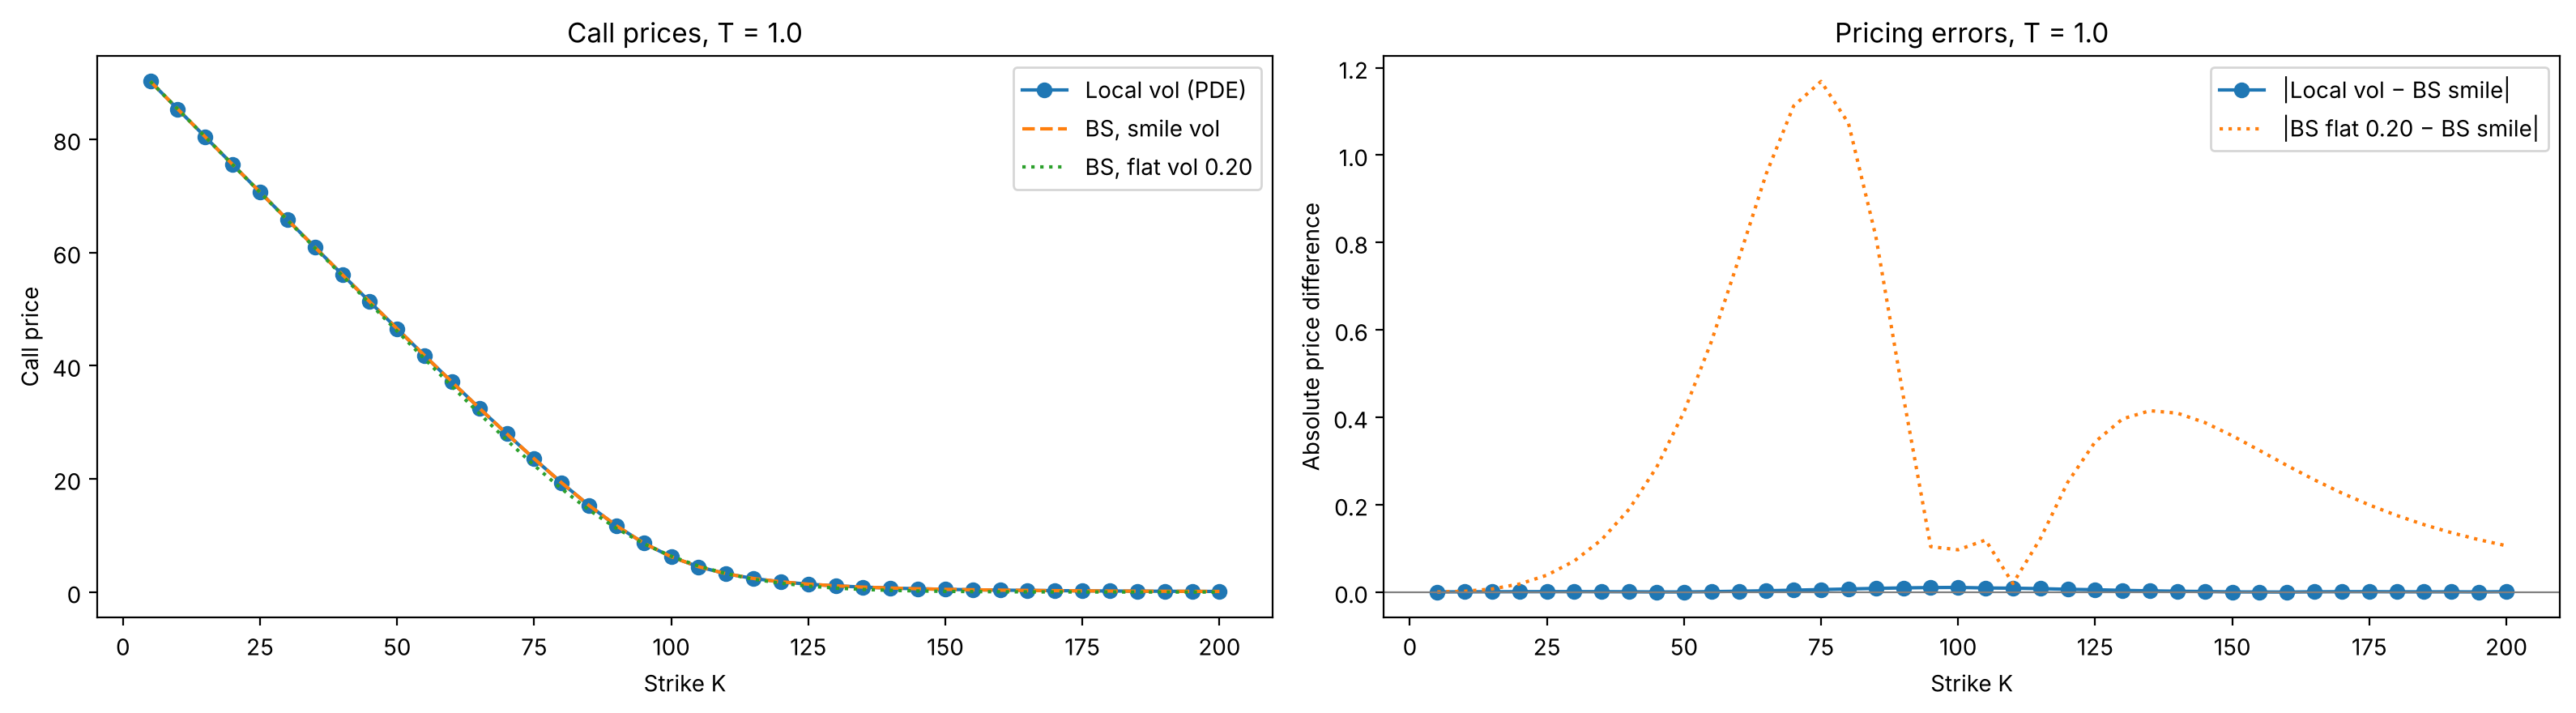

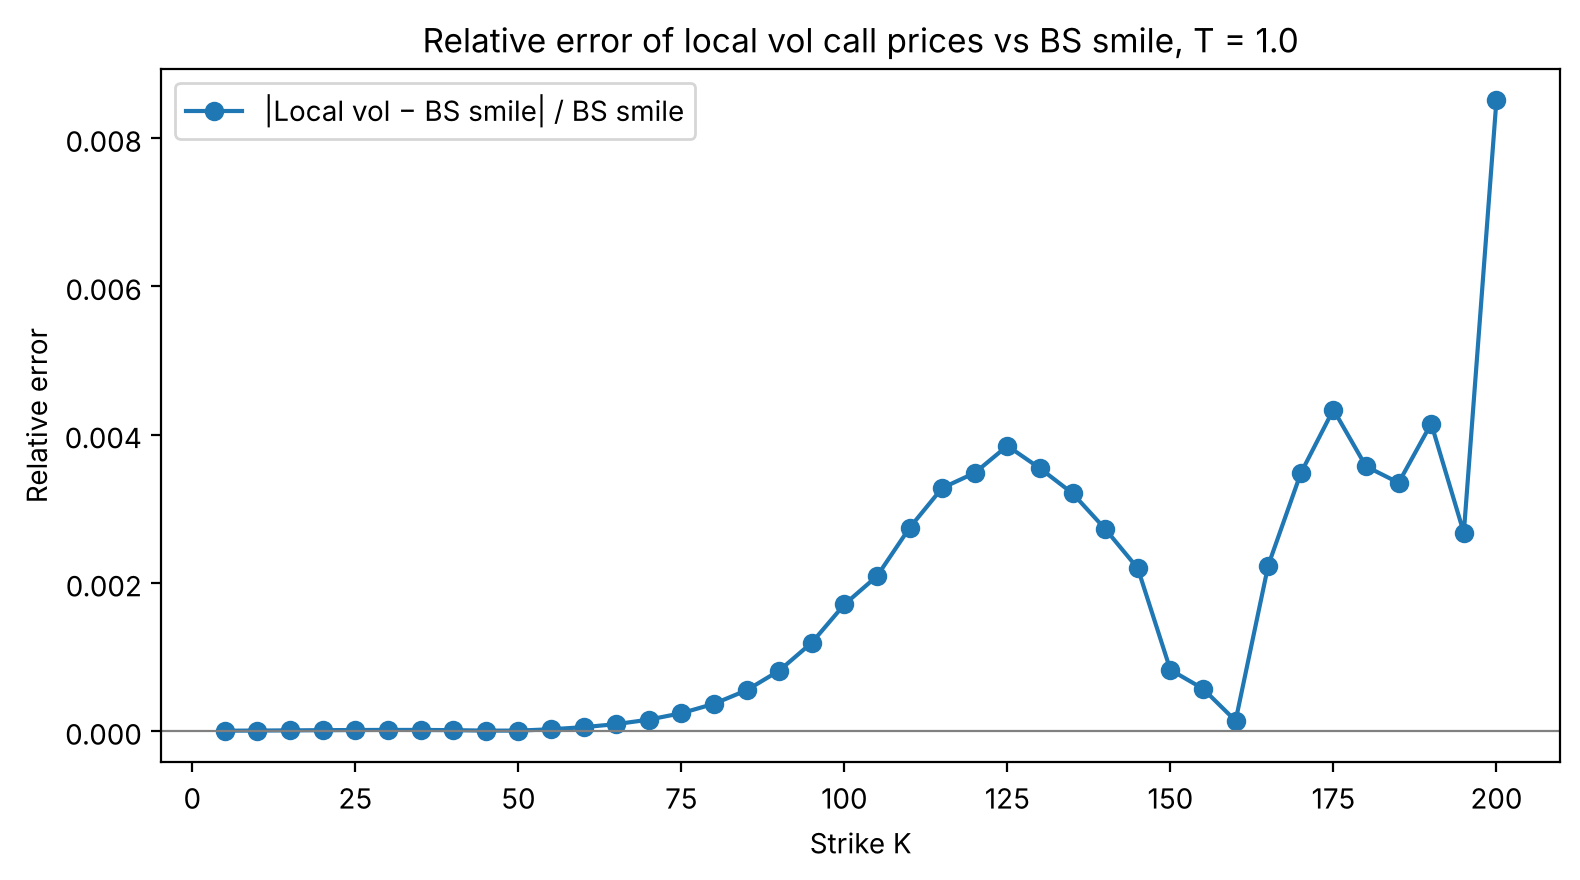

Max absolute error: 0.0106 (K = 100)
Max effect of the smile (|BS flat − BS smile|): 1.1687


In [7]:
K_test = np.arange(5, 201, 5)

# Local volatility prices
lv_prices = np.array([fdm_price(S0=100, K=K, T=T_test, r=r, q=q, sigma=sigma)[0] for K in K_test])

# Black-Scholes benchmarks
bs_smile = np.array([bs_price(100, K, T_test, r, q, implied_vol(K), option_type='call') for K in K_test])
bs_flat  = np.array([bs_price(100, K, T_test, r, q, 0.20, option_type='call') for K in K_test])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(K_test, lv_prices, 'o-', label='Local vol (PDE)')
axes[0].plot(K_test, bs_smile, '--', label='BS, smile vol')
axes[0].plot(K_test, bs_flat, ':', label='BS, flat vol 0.20')
axes[0].set(xlabel='Strike K', ylabel='Call price', title=f'Call prices, T = {T_test}')
axes[0].legend()

axes[1].plot(K_test, abs(lv_prices - bs_smile), 'o-', label='|Local vol − BS smile|')
axes[1].plot(K_test, abs(bs_flat - bs_smile), ':', label='|BS flat 0.20 − BS smile|')
axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set(xlabel='Strike K', ylabel='Absolute price difference', title=f'Pricing errors, T = {T_test}')
axes[1].legend()

plt.tight_layout()
plt.show()

# Relative errors
rel_error_lv = abs(lv_prices - bs_smile) / bs_smile
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(K_test, rel_error_lv, 'o-', label='|Local vol − BS smile| / BS smile')
ax.axhline(0, color='grey', lw=0.8)
ax.set(xlabel='Strike K', ylabel='Relative error',
       title=f'Relative error of local vol call prices vs BS smile, T = {T_test}')
ax.legend()
plt.tight_layout()
plt.show()

err = np.abs(lv_prices - bs_smile)
print(f"Max absolute error: {err.max():.4f} (K = {K_test[err.argmax()]})")
print(f"Max effect of the smile (|BS flat − BS smile|): {np.abs(bs_flat - bs_smile).max():.4f}")

**Results.** The local volatility model reproduces the Black-Scholes prices of the smile with a maximum absolute error of about 0.011 (at the money), while the smile itself moves prices by up to 1.17 compared with a flat 0.20 volatility. The chain prices → Dupire → PDE → prices is therefore consistent.

The remaining error has two sources. Near the money, it comes from the PDE discretization (first order in time, grid step $\Delta S = 0.5$). For high strikes, the relative error grows up to about 1%: these calls are worth almost nothing, and the local vol surface there relies on one-sided differences at the edge of the grid and on the filled NaN points.

## 6. Application: delta hedging

A model calibrated to vanilla prices cannot find mispriced vanillas: it reprices them at the market price by construction. Its practical use is elsewhere: **hedging**, and pricing other products consistently with the vanillas. This section tests the hedging side.

**Setup.** We sell one at-the-money call ($K = 100$, $T = 1$) at its market price and delta-hedge it every trading day (252 rebalancings) with the underlying, financing the position at $r$ and receiving the dividend yield $q$. At maturity, the hedging P&L is

$$
\text{P\&L} = \text{premium} \cdot e^{rT} + \text{gains of the stock position} - \max(S_T - K, 0).
$$

A perfect hedge gives a P&L of zero on every path; the **standard deviation of the P&L** measures how well a delta works. Two deltas are compared:

- **Black-Scholes delta**, computed with the option's implied vol kept fixed when the spot moves (*sticky strike*);
- **local vol delta** $\partial V / \partial S$, read on the PDE solution, which accounts for the skew: the local vol changes with the spot.

The local vol surface computed by finite differences in section 3 is unusable close to $t = 0$ (values above 100 at $t = 0.01$), and the deltas built from it are wrong. The hedging tests therefore use the **analytic local vol** of the same SVI smile, given by Gatheral's formula in total implied variance $w(y, t) = \sigma_{\text{imp}}^2 t$, with $y = \ln(K / F(t))$:

$$
\sigma_{\text{loc}}^2 = \frac{\partial_t w}{\left(1 - \dfrac{y\, \partial_y w}{2w}\right)^2 - \dfrac{(\partial_y w)^2}{4}\left(\dfrac{1}{w} + \dfrac{1}{4}\right) + \dfrac{\partial_y^2 w}{2}}
$$

In [8]:
def bs_delta(S, K, tau, r, q, sigma):
    # Black-Scholes call delta (vectorized in S)
    tau = np.maximum(tau, 1e-10)
    d1_ = (np.log(S / K) + (r - q + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return np.exp(-q * tau) * norm.cdf(d1_)

def fdm_solve_surface(K, T, r, q, sigma, S_max, M=800, N=504):
    # Same implicit scheme as fdm_price, but keeps the whole solution V(S, t_n)
    S = np.linspace(0.0, S_max, M + 1)
    dS, dt = S[1] - S[0], T / N
    Si = S[1:-1]
    V = np.empty((N + 1, M + 1))
    V[N] = np.maximum(S - K, 0.0)
    for n in range(N - 1, -1, -1):
        t = n * dt
        sig = sigma(Si, t)
        alpha = 0.5 * sig**2 * Si**2 / dS**2
        beta = (r - q) * Si / (2 * dS)
        a_, b_, c_ = alpha - beta, -2 * alpha - r, alpha + beta
        C_up = S_max * np.exp(-q * (T - t)) - K * np.exp(-r * (T - t))
        rhs = V[n + 1, 1:-1].copy()
        rhs[-1] += dt * c_[-1] * C_up
        ab = np.zeros((3, M - 1))
        ab[0, 1:] = -dt * c_[:-1]
        ab[1, :] = 1 - dt * b_
        ab[2, :-1] = -dt * a_[1:]
        V[n, 1:-1] = solve_banded((1, 1), ab, rhs)
        V[n, 0], V[n, -1] = 0.0, C_up
    return S, np.linspace(0, T, N + 1), V

def local_vol_delta_fn(K, T, r, q, sigma, n_hedge, S_max=400.0):
    # Δ(S, t_n) = ∂V/∂S on the PDE grid, at the hedging dates
    sub = 2
    S, t, V = fdm_solve_surface(K, T, r, q, sigma, S_max, N=n_hedge * sub)
    D = np.gradient(V, S, axis=1)[::sub]          # shape (n_hedge + 1, M + 1)
    price = np.interp(S0, S, V[0])
    return (lambda n, Sn: np.interp(Sn, S, D[n])), price

def simulate_local_vol_paths(S0, T, r, q, sigma, n_paths, n_hedge, sub=4, seed=1, vmax=2.0):
    # Euler scheme on ln S under the local vol model, `sub` steps per hedging date
    rng = np.random.default_rng(seed)
    dt = T / (n_hedge * sub)
    lnS = np.full(n_paths, np.log(S0))
    paths = np.empty((n_hedge + 1, n_paths))
    paths[0] = S0
    for i in range(n_hedge * sub):
        sig = np.clip(sigma(np.exp(lnS), i * dt), 0.01, vmax)
        lnS += (r - q - 0.5 * sig**2) * dt + sig * np.sqrt(dt) * rng.standard_normal(n_paths)
        if (i + 1) % sub == 0:
            paths[(i + 1) // sub] = np.exp(lnS)
    return paths

def hedge_pnl(paths, K, T, r, q, premium, delta_fn):
    # Sell one call for `premium`, delta-hedge at each date; P&L at maturity
    n_hedge = paths.shape[0] - 1
    dt = T / n_hedge
    delta = delta_fn(0, paths[0])
    cash = premium - delta * paths[0]
    for n in range(n_hedge):
        S_next = paths[n + 1]
        cash = cash * np.exp(r * dt) + delta * S_next * (np.exp(q * dt) - 1)   # interest + dividends
        if n + 1 < n_hedge:
            new_delta = delta_fn(n + 1, S_next)
            cash -= (new_delta - delta) * S_next                               # rebalancing
            delta = new_delta
    return cash + delta * paths[-1] - np.maximum(paths[-1] - K, 0.0)

def summarize(name, pnl, premium):
    print(f"{name:28s} | mean {pnl.mean():+.3f} | std {pnl.std():.3f} ({pnl.std() / premium:.1%} of premium) "
          f"| 5% quantile {np.quantile(pnl, 0.05):+.3f}")

In [9]:
def svi_variance(k1):
    x = k1 - m
    R = np.sqrt(x**2 + s**2)
    return a + b * (rho * x + R), b * (rho + x / R), b * s**2 / R**3

def sigma_analytic(S, t):
    t = max(t, 1e-6)
    y = np.log(S / (S0 * np.exp((r - q) * t)))
    k1 = y + (r - q) * (t - T_test)
    v, v1, v2 = svi_variance(k1)
    w, wy, wyy, wt = v * t, v1 * t, v2 * t, v + t * v1 * (r - q)
    g = (1 - y * wy / (2 * w)) ** 2 - 0.25 * wy**2 * (1 / w + 0.25) + 0.5 * wyy
    return np.sqrt(wt / g)

### Experiment A: the world follows the local vol model

The paths are simulated with the local vol model itself. The local vol delta is then the right delta, and its remaining error only comes from rebalancing once a day: for an ATM option, the theoretical order of magnitude of this discretization error is $\sqrt{\pi / (4N)}\, \sigma\, \text{vega} \approx 0.42$ with $N = 252$.

Market price 6.2334 | local vol PDE price 6.2321


BS delta                     | mean +0.003 | std 0.726 (11.7% of premium) | 5% quantile -1.106
Local vol delta              | mean -0.002 | std 0.462 (7.4% of premium) | 5% quantile -0.755


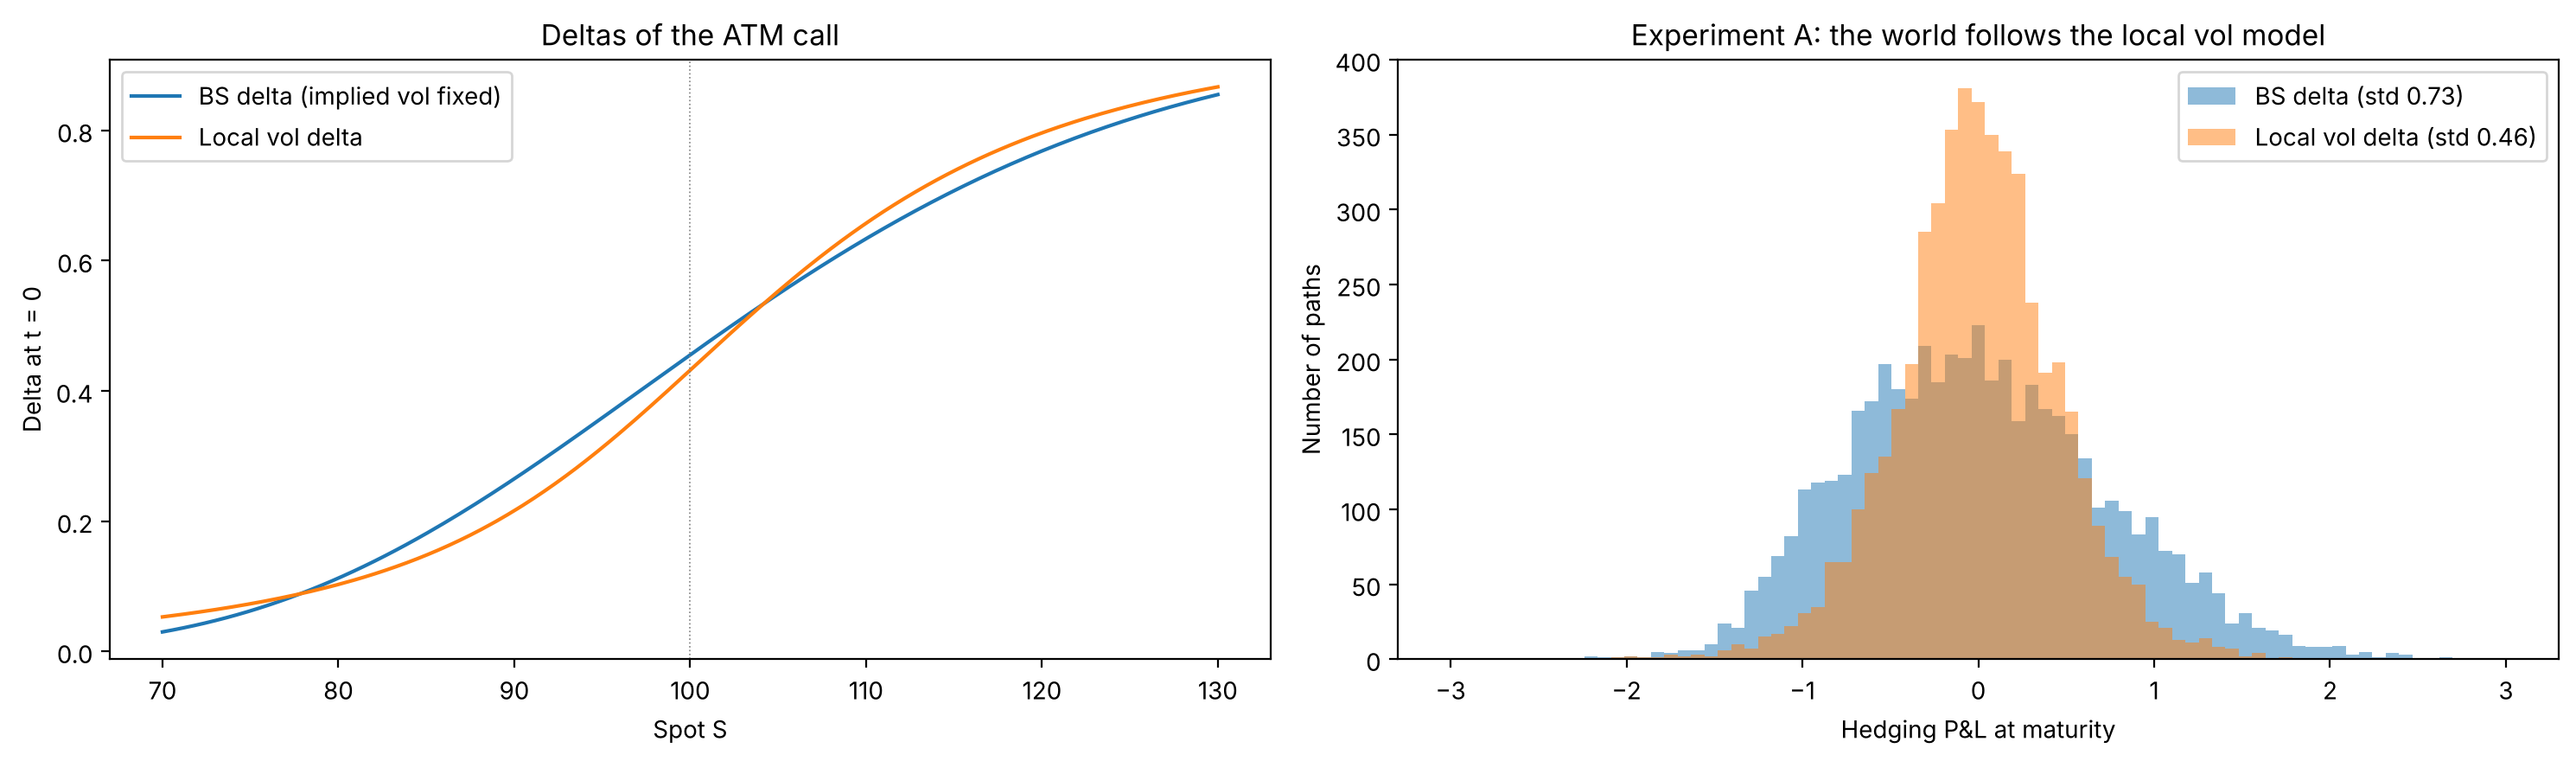

In [10]:
K_h, T_h, n_hedge, n_paths = 100.0, 1.0, 252, 5000    # short 1 ATM call, 1 year, daily rebalancing
dt_h = T_h / n_hedge
sigma_K = implied_vol(K_h)
premium = bs_price(S0, K_h, T_h, r, q, sigma_K)        # market price of the call

lv_delta, lv_price = local_vol_delta_fn(K_h, T_h, r, q, sigma_analytic, n_hedge)
bs_delta_fn = lambda n, Sn: bs_delta(Sn, K_h, T_h - n * dt_h, r, q, sigma_K)   # implied vol kept fixed
print(f"Market price {premium:.4f} | local vol PDE price {lv_price:.4f}")

paths_lv = simulate_local_vol_paths(S0, T_h, r, q, sigma_analytic, n_paths, n_hedge)
pnl_A = {"BS delta": hedge_pnl(paths_lv, K_h, T_h, r, q, premium, bs_delta_fn),
         "Local vol delta": hedge_pnl(paths_lv, K_h, T_h, r, q, premium, lv_delta)}
for name, pnl in pnl_A.items():
    summarize(name, pnl, premium)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
S_plot = np.linspace(70, 130, 200)
axes[0].plot(S_plot, bs_delta_fn(0, S_plot), label="BS delta (implied vol fixed)")
axes[0].plot(S_plot, lv_delta(0, S_plot), label="Local vol delta")
axes[0].axvline(K_h, color="grey", lw=0.6, ls=":")
axes[0].set(xlabel="Spot S", ylabel="Delta at t = 0", title="Deltas of the ATM call")
axes[0].legend()
bins = np.linspace(-3, 3, 80)
for name, pnl in pnl_A.items():
    axes[1].hist(pnl, bins=bins, alpha=0.5, label=f"{name} (std {pnl.std():.2f})")
axes[1].set(xlabel="Hedging P&L at maturity", ylabel="Number of paths",
            title="Experiment A: the world follows the local vol model")
axes[1].legend()
plt.tight_layout()
plt.show()

The local vol delta reaches the discretization floor (standard deviation ≈ 0.46, about 7% of the premium), while the Black-Scholes delta adds a model error on top of it (≈ 0.73, about 12%). With this smile, the local vol delta is lower than the BS delta at the money and higher further in the money: it anticipates that the volatility of the option changes when the spot moves.

This test is favourable to local vol by construction: the model used to hedge is the model that generated the paths. The question we could ask ourselves is what happens when the world does **not** follow the local vol model. 

**Takeaways for a desk**

- A local vol model is the right tool to price **consistently with the vanillas** and to obtain a **skew-aware delta**, which is better than the Black-Scholes delta when the spot and the volatility are negatively correlated, as on equity indices.
- It does **not** generate trading signals on the vanillas it is calibrated to, and its hedges carry **model risk**: the residual risk is mostly vega, and needs to be hedged with other options (delta-vega hedging), not with the underlying.
- Products whose price depends on the future dynamics of the smile (forward-starting options, cliquets, some barriers) are where local vol and stochastic vol disagree most, and where the choice of model matters.

## 7. Tests on real market data

The same approach was tested on **S&P 500 index options** (`^SPX`, European, loaded with `yfinance`: 8 expiries from 2 weeks to about 1.6 years, about 2,100 out-of-the-money quotes). The code is in `local_vol_market.py`. Real quotes required several changes:

- **Forward and discounting from put-call parity.** Instead of assuming $r$ and $q$, the forward $F(T)$ and discount factor $D(T)$ of each expiry are read from $C - P = D(F - K)$, and options are priced with Black's formula on the forward. One expiry gave an implausible discount factor ($D = 1.023$, i.e. $r = -17\%$), so the discount curve is now fitted robustly across maturities.
- **Smoothing before differentiating.** Market prices are noisy, so the smile is fitted first (one SVI slice per maturity, on out-of-the-money options, weighted by the bid-ask spread), and the local vol is computed **analytically** from the fit with Gatheral's formula, instead of finite differences on prices. A single SSVI surface, arbitrage-free by construction, was tried first but was too rigid for the very steep short-dated skew of the SPX: its parameters hit their no-arbitrage bounds and the fit error reached about 180 vol bp.
- **Wings and grids.** Beyond the last quoted strike, total variance is extended linearly within Lee's bound (the raw SVI extrapolation produced exploding wings and butterfly arbitrage). The PDE is solved in $\ln S$ with Crank-Nicolson, on a grid sized to each maturity: the uniform grid in $S$ had only about 4 nodes per standard deviation for a 2-week option.

On a synthetic SPX-like chain, the final version reprices the quotes with a median error of about 2 vol bp (11 bp at most), 96% of prices falling inside the bid-ask spread. Dupire with finite differences on the same surface fails at short maturities: 80 to 88% of the grid is unusable below $t = 0.03$, the remaining points contain spikes, and the round-trip errors reach several hundred vol bp. The final version still has to be rerun on live SPX quotes, during US market hours.

## 8. Limitations and next steps

- **Short maturities**: Dupire on prices is unstable near $T = 0$; the implied-volatility form of Dupire (Gatheral) avoids differentiating prices altogether.
- **Discretization**: the implicit scheme is first-order in time; Crank-Nicolson with Rannacher smoothing is second-order.
- **Model limits**: local volatility reproduces today's vanilla prices exactly, but it misrepresents the dynamics of the smile and predicts a forward smile that flattens over time, which misprices forward-starting and some path-dependent products. Stochastic or local-stochastic volatility models address this.
- **Hedging**: extend section 6 to hedging when the volatility follows another model (e.g Heston) and delta-vega hedging with a second option, add transaction costs, and backtest on historical SPX paths.